# Lab 08: How to give an agent a document search tool

**CPU | API key: `OPENAI_API_KEY` | In class**

A rep asks the copilot three things: what to do about a duplicate charge, whether Chinook matches a lower price, and
for a warmer greeting. The first two are about the shop's rules, and only the first has an answer in the support
handbook. In this lab you give the copilot a search over the handbook as a tool, and it decides when to use it.

## Goal

Give an agent a tool that searches the support handbook, so that it answers rule questions from the handbook, names
the file each rule came from, and says so when the handbook has no answer. The moment that teaches it: asked for a
warmer greeting, the agent does not search; asked about the duplicate charge, it searches and cites
`policy_refunds.md`; asked about price matching, which no policy covers, it searches, finds nothing that answers, and
says the handbook does not cover it (5 of 5 runs for each question on `gpt-4o-mini`).

## What you will learn

- How to load the handbook into a vector store, with each section's file and title as metadata.
- How to answer from the handbook in two steps by hand: search in your code, then one model call with the passages.
- How to give an agent the same search as a tool, and see when it decides to call it.
- How to make the agent cite its sources and say when the handbook has no answer.
- How to check citations and abstention in code, from the files the tool returned.
- How to catch a citation that does not support its claim, with a quote your code looks up.

## Set up the notebook

Run these two cells first, every time; Lab 00 explains each line. **Setup** finds the repository folder (on Colab it
copies the repository and installs the packages first). **Config** reads `models.env` and finds your key. This lab
uses `CHAT_MODEL` for the copilot and `EMBED_MODEL` for the search.

In [1]:
# Setup: on Colab, copy the repository and install the packages. Locally (after uv sync) nothing is installed.
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/agentic_ai_conversational_agents").exists():
        !git clone -q --depth 1 https://github.com/tatwan/agentic_ai_conversational_agents.git /content/agentic_ai_conversational_agents
    %cd /content/agentic_ai_conversational_agents
    %pip install -q -r requirements.txt

ROOT = next(folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / "models.env").exists())
sys.path.insert(0, str(ROOT))
print("Repository folder:", ROOT.name)

Repository folder: agentic_ai_conversational_agents


⚠️ On Colab, run the setup cell first in a fresh session. If another cell loaded the old `openai` package before the
install, the first model call fails with `ImportError: cannot import name ... from 'openai...'`; use **Runtime →
Restart session** and run from the top.

In [2]:
# Config: model names come from models.env; the key from the environment, .env or Colab Secrets.
from shared.settings import load_settings, load_key

settings = load_settings()
key_found_in = load_key("OPENAI_API_KEY")

for name in ("CHAT_MODEL", "REASONING_EFFORT", "EMBED_MODEL"):
    print(f"{name:18}{settings[name] or '(not set)'}")
print(f"{'OPENAI_API_KEY':18}{'found in ' + key_found_in if key_found_in else 'not found'}")

CHAT_MODEL        gpt-4o-mini
REASONING_EFFORT  (not set)
EMBED_MODEL       text-embedding-3-small
OPENAI_API_KEY    found in .env


The picture shows the two ways this lab answers from the handbook. On the left your code always searches; on the
right the model first decides whether the question needs the handbook. Both answers go through the same checks.

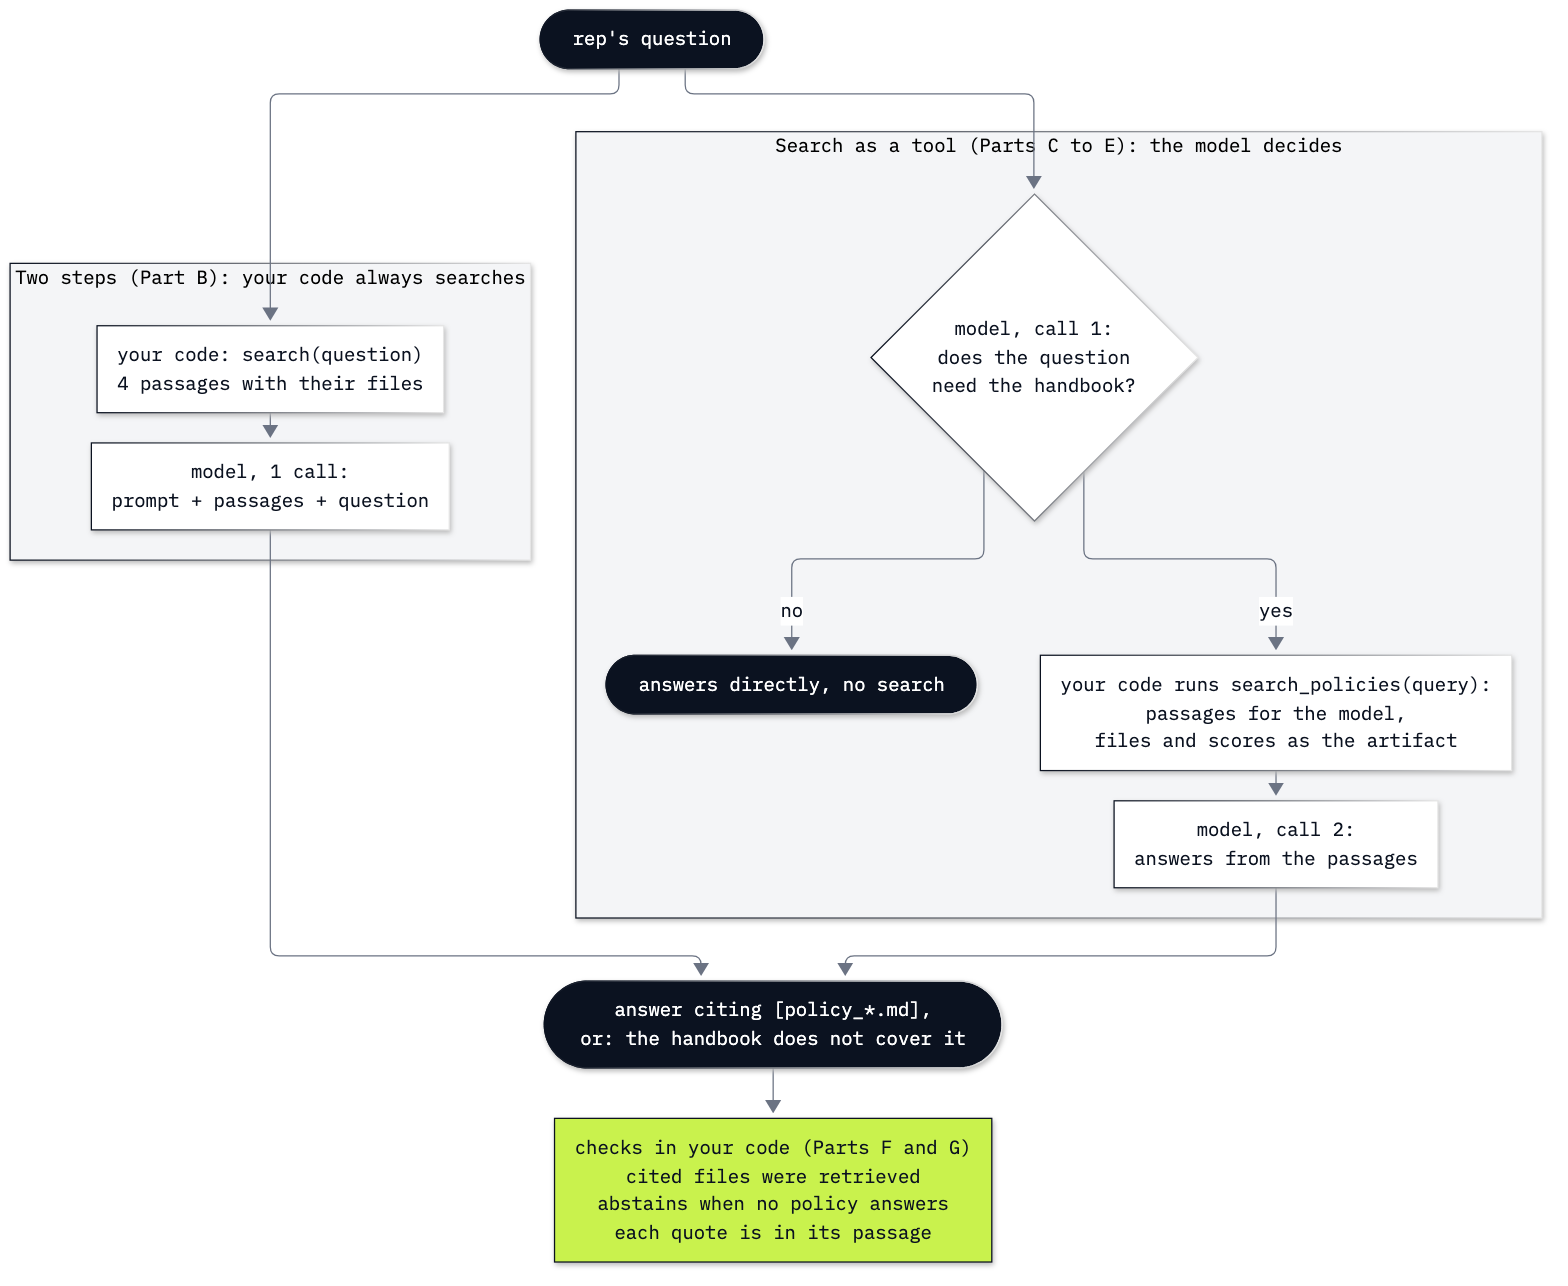

In [3]:
from IPython.display import Image
Image(filename=ROOT / "08_RAG_Citations_Abstention" / "resources" / "search_tool.png", width=620)

---

## Part A: Load the handbook into a vector store

Part A builds what the copilot will search: the handbook's 20 policies, each kept with the file it came from.

Two terms first. An **embedding** is a list of numbers an embedding model (`EMBED_MODEL`) computes from a text, so
that texts with similar meanings get similar numbers. A **vector store** keeps one embedding per piece of text,
together with the text and any **metadata** you attach (here the file and the section title), and returns the pieces
closest to a question. LangChain's `InMemoryVectorStore` does this in memory, with no extra package, which is enough for a
few dozen policies ([vector stores](https://docs.langchain.com/oss/python/integrations/vectorstores)). The self-study
Lab 07 shows the search underneath; you do not need it here.

The handbook is one markdown file with a `##` heading per policy. Split it at those headings, so each policy is one
piece.

In [4]:
from langchain_text_splitters import MarkdownHeaderTextSplitter

handbook = (ROOT / "data" / "handbook" / "support_handbook.md").read_text(encoding="utf-8")
splitter = MarkdownHeaderTextSplitter(headers_to_split_on=[("##", "section")], strip_headers=False)
sections = [part for part in splitter.split_text(handbook) if "section" in part.metadata]  # skip the title paragraph

print(len(sections), "sections")
print(sections[13].metadata)
print(sections[13].page_content)

20 sections
{'section': 'Refunds'}
## Refunds
Source: policy_refunds.md  
Refunds go back to the original payment method. They take 5 to 10 business days after support approves the request.  
Partial refunds are allowed when only some tracks on a multi-disc set are defective.  
We do not refund because a customer changed their mind about a digital purchase.  
Duplicate charges: if two invoices exist for the same album on the same day, refund the later invoice in full. Attach both invoice numbers.


Each section has its title in `metadata` and names its file on a `Source:` line. The copilot will cite that file, so
move it into the metadata too, where code can read it without parsing text. A `Document` is LangChain's container
for a text and its metadata.

In [5]:
from langchain_core.documents import Document

documents = []
for part in sections:
    source = part.page_content.split("Source: ")[1].split()[0]
    text = part.page_content.replace(f"Source: {source}", "").strip()
    documents.append(Document(page_content=text, metadata={"source": source, "section": part.metadata["section"]}))

print(documents[13].metadata)

{'source': 'policy_refunds.md', 'section': 'Refunds'}


Now the store. It takes the embedding model; `add_documents` embeds all 20 texts in one call and keeps each vector
beside its text and metadata.

In [6]:
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_openai import OpenAIEmbeddings

vector_store = InMemoryVectorStore(OpenAIEmbeddings(model=settings["EMBED_MODEL"]))
ids = vector_store.add_documents(documents)
print(len(ids), "documents in the store")

20 documents in the store


### Checkpoint A

| You should see | Our run |
|---|---|
| Sections | 20; section 13 is `{'section': 'Refunds'}` with a `Source: policy_refunds.md` line |
| Metadata | `{'source': 'policy_refunds.md', 'section': 'Refunds'}` |
| Store | 20 documents |

---

## Part B: Search, then answer in two steps

Part B answers from the handbook the plainest way: your code searches for every question, then calls the model once
with what it found. The LangChain docs call this **two-step RAG**, for retrieval-augmented generation
([retrieval](https://docs.langchain.com/oss/python/deepagents/retrieval)).

Search first, as a plain function. `similarity_search_with_score` embeds the question and returns the closest
documents with their **cosine similarity**: higher means closer in meaning, but it is not a probability.

In [7]:
def search(query, k=4):
    """The k handbook sections closest to the query, best first, as (document, score) pairs."""
    return vector_store.similarity_search_with_score(query, k=k)

question = "A customer was charged twice for the same album on the same day. What do we do?"
for doc, score in search(question):
    print(f"{score:.4f}  {doc.metadata['source']:28} {doc.metadata['section']}")

0.4807  policy_refunds.md            Refunds
0.4515  policy_damaged_media.md      Damaged media
0.4124  policy_exchanges.md          Exchanges
0.3906  policy_digital_downloads.md  Digital downloads


The refunds section comes first (0.4807), and it holds the duplicate-charge rule. The other three are close in meaning (a damaged album, an exchange, a digital download) and say nothing about being charged twice. Why four results and not three? Search with the shorter words a model might choose:

In [8]:
for doc, score in search("charged twice for the same album"):
    print(f"{score:.4f}  {doc.metadata['source']}")

0.3874  policy_damaged_media.md
0.3404  policy_digital_downloads.md
0.3394  policy_exchanges.md
0.3391  policy_refunds.md


With the words *charged twice for the same album*, the refunds section drops to fourth (0.3391), behind damaged media, digital downloads and exchanges. With three results it would be missing. The words of the query decide what comes back, and a fourth result gives a short query some room.

Step two: put the passages in the message, each starting with its file in square brackets, and call the model once.
`chat_model(settings)` returns the model `CHAT_MODEL` names in `models.env`, called through OpenAI's Responses API
(Lab 00). The prompt has one rule: answer only from the passages.

In [9]:
from shared.settings import chat_model

passages = "\n\n".join(f"[{doc.metadata['source']}]\n{doc.page_content}" for doc, score in search(question))
TWO_STEP_PROMPT = ("You are the Chinook support copilot. You help support reps answer customer emails. "
                   "Answer only from the handbook passages in the message.")

model = chat_model(settings)
reply = model.invoke([("system", TWO_STEP_PROMPT), ("user", f"Handbook passages:\n{passages}\n\nRep: {question}")])
print(reply.text)

If two invoices exist for the same album on the same day, we refund the later invoice in full. Please attach both invoice numbers when processing the refund.


The reply gives the rule from the refunds passage: refund the later invoice in full and attach both invoice numbers. Nothing came from the other three passages.

Two steps always search: predictable, and wasteful when a rep asks for a warmer greeting, because your code still
sends four policies the model does not need.

### Checkpoint B

| You should see | Our run |
|---|---|
| Top 4 for the rep's question | `policy_refunds.md` 0.4807, `policy_damaged_media.md` 0.4515, `policy_exchanges.md` 0.4123, `policy_digital_downloads.md` 0.3906 |
| The shorter query | `policy_refunds.md` fourth, 0.3391 |
| The reply | the duplicate-charge rule: refund the later invoice in full, attach both invoice numbers |

---

## Part C: Give the agent the search as a tool

Part C hands the decision to the model: it reads the question, decides whether it needs the handbook, and if so
writes its own search words. The docs call this **agentic RAG**.

The tool wraps the same `search`. It returns two things ([messages](https://docs.langchain.com/oss/python/langchain/messages)):
the **content**, the passages the model reads, and an **artifact**, data your code keeps on the tool message and the
model never sees. Here the artifact lists the files and scores, so your code knows exactly what the model was given.
`response_format="content_and_artifact"` switches this on; the function returns the pair.

In [10]:
from langchain.tools import tool

@tool(parse_docstring=True, response_format="content_and_artifact")
def search_policies(query: str) -> tuple[str, list[dict]]:
    """Search the support handbook for the four passages closest to a query.

    Call it before answering any question about shop rules.
    Each passage starts with its source file in square brackets.

    Args:
        query: What the rep needs to know, in a short sentence.
    """
    hits = search(query)
    content = "\n\n".join(f"[{doc.metadata['source']}]\n{doc.page_content}" for doc, score in hits)
    found = [{"source": doc.metadata["source"], "score": round(score, 4)} for doc, score in hits]
    return content, found

Run it the way the agent will, with a tool call. A tool called with a tool call returns a `ToolMessage`, which holds
both parts.

In [11]:
call = {"type": "tool_call", "id": "call_1", "name": "search_policies", "args": {"query": question}}
message = search_policies.invoke(call)
print(message.content[:150], "...")
print("artifact:", message.artifact)

[policy_refunds.md]
## Refunds
  
Refunds go back to the original payment method. They take 5 to 10 business days after support approves the request.  ...
artifact: [{'source': 'policy_refunds.md', 'score': 0.4807}, {'source': 'policy_damaged_media.md', 'score': 0.4515}, {'source': 'policy_exchanges.md', 'score': 0.4124}, {'source': 'policy_digital_downloads.md', 'score': 0.3906}]


Now the agent: `create_agent` from Lab 01, with this tool and a short prompt that says when to search.

In [12]:
from langchain.agents import create_agent

PROMPT = """You are the Chinook support copilot. You help support reps answer customer emails.
Use search_policies for any question about the shop's rules, and answer only from the passages it returns."""

agent = create_agent(model, tools=[search_policies], system_prompt=PROMPT)

A small function prints a run: the search words the model wrote, the files that came back (read from the artifact)
and the reply. Ask the duplicate charge and the greeting. Predict before you run: will the agent search for both?

In [13]:
def show(messages):
    for message in messages[1:]:
        if message.type == "ai" and message.tool_calls:
            print("ai    searches for:", [call["args"]["query"] for call in message.tool_calls])
        elif message.type == "tool":
            print("tool  files:", [hit["source"] for hit in message.artifact])
        else:
            print("ai   ", message.text)

QUESTIONS = {
    "duplicate charge": question,
    "greeting": "Make this greeting warmer for a customer: 'Hello Helena, we got your email.'",
    "price match": "A customer found the same album cheaper at another store. Do we match a lower price?",
}
for label in ("duplicate charge", "greeting"):
    print(f"--- {label}")
    show(agent.invoke({"messages": [("user", QUESTIONS[label])]})["messages"])

--- duplicate charge


ai    searches for: ['customer charged twice for the same album']
tool  files: ['policy_damaged_media.md', 'policy_refunds.md', 'policy_exchanges.md', 'policy_digital_downloads.md']
ai    If a customer has been charged twice for the same album on the same day, you should refund the later invoice in full. Be sure to attach both invoice numbers for reference.
--- greeting


ai    Here's a warmer greeting for Helena:

"Hi Helena! Thank you for reaching out to us. We appreciate your email and are here to help!"


For the duplicate charge the model wrote its own search words, *customer charged twice for the same album*, close to Part B's short query; the refunds section came back second, and the reply gives the rule. For the greeting the model did not search: one model call. No code chose; the prompt's line about the shop's rules and the tool's description did.

### Checkpoint C

| You should see | Our run |
|---|---|
| The artifact | four `{'source': ..., 'score': ...}` dictionaries, `policy_refunds.md` first at 0.4807 |
| Duplicate charge | one search (ours: *customer charged twice for the same album*), `policy_refunds.md` among the files, the reply gives the rule |
| Greeting | no search: one AI message, a warmer greeting |

---

## Part D: Cite the file each rule came from

Part D makes the answer checkable: after each rule, the file it came from. The passages already start with their file
in square brackets, so one prompt line is enough. Ask the duplicate charge again, and the price question, which no
policy covers.

In [14]:
CITE_PROMPT = PROMPT + "\nAfter each rule you use, name its file in square brackets, for example [policy_refunds.md]."
cite_agent = create_agent(model, tools=[search_policies], system_prompt=CITE_PROMPT)

cited_runs = {label: cite_agent.invoke({"messages": [("user", QUESTIONS[label])]})["messages"]
              for label in ("duplicate charge", "price match")}
for label, messages in cited_runs.items():
    print(f"--- {label}")
    show(messages)

--- duplicate charge
ai    searches for: ['charged twice for the same album']
tool  files: ['policy_damaged_media.md', 'policy_digital_downloads.md', 'policy_exchanges.md', 'policy_refunds.md']
ai    If a customer was charged twice for the same album on the same day, you should refund the later invoice in full. Make sure to attach both invoice numbers in your response. Refunds typically take 5 to 10 business days after approval. [policy_refunds.md]
--- price match
ai    searches for: ['price matching policy']
tool  files: ['policy_exchanges.md', 'policy_payment.md', 'policy_escalations.md', 'policy_refunds.md']
ai    We do not have a price matching policy. However, if a customer wants to exchange an album because they found it cheaper elsewhere, they can return their original purchase and place a new order for the cheaper item, paying any price difference. If the new item is cheaper, we will refund the difference. This process must be done within the 30-day unopened window for exchange

The duplicate charge now ends with `[policy_refunds.md]`. The price question is the problem. Our reply opens *We do not have a price matching policy*, then offers a way round it from `[policy_exchanges.md]`: return the album, place a new order for the cheaper item, and get the difference back. In 8 more tries on `gpt-4o-mini`, 6 said *We do not match lower prices from other stores* outright and 2 gave the same way round, all citing `policy_exchanges.md`. Read that file's passage, as a rep would.

In [15]:
TEXT = {doc.metadata["source"]: doc.page_content for doc in documents}
print(TEXT["policy_exchanges.md"])

## Exchanges
  
An exchange is a return plus a new order. The customer pays any price difference. If the new item is cheaper, we refund the difference.  
Exchanges use the same 30-day unopened window as returns.  
We do not exchange a digital album for a vinyl pressing of the same title without a new paid order.


The exchanges policy says an exchange is a return plus a new order, with the price difference paid or refunded. It says nothing about matching another store's price, and an exchange swaps one of the shop's items for another, so it is no route to a lower price elsewhere. The file is real and the tool returned it, and the answer is still made up: a flat rule in most tries, a rule stretched to fit in ours. No policy covers price matching, so the right answer was to say so.

### Checkpoint D

| You should see | Our run |
|---|---|
| Duplicate charge | the rule, ending `[policy_refunds.md]` |
| Price match | an answer the handbook does not give, citing `[policy_exchanges.md]`: most often *We do not match lower prices from other stores* (6 of 8 tries); ours, a way round through an exchange |

If your price reply says the handbook does not cover it, your model did not invent a rule this time (ours invented one
in 9 of 9 tries). Run the cell again, or go on: Part F's last check then shows `abstained: True`, and Part G's hand
test checks the invented rule without the model.

---

## Part E: Say when the handbook has no answer

Part E adds **abstention**: when the passages do not answer the question, the copilot says so and sends the rep to
someone who can decide, instead of guessing. One more prompt line. Model replies vary, so ask each of the three
questions five times.

In [16]:
ABSTAIN_PROMPT = CITE_PROMPT + ("\nIf the passages do not answer the question, say that the handbook does not cover it "
                                "and suggest asking the support manager. Do not guess.")
copilot = create_agent(model, tools=[search_policies], system_prompt=ABSTAIN_PROMPT)

runs = {label: [copilot.invoke({"messages": [("user", q)]})["messages"] for _ in range(5)]
        for label, q in QUESTIONS.items()}
for label, label_runs in runs.items():
    for messages in label_runs:
        searches = sum(m.type == "tool" for m in messages)
        print(f"{label:16} | searches {searches} | {messages[-1].text[:95]}")

duplicate charge | searches 1 | If a customer was charged twice for the same album on the same day, you should refund the later
duplicate charge | searches 1 | If a customer was charged twice for the same album on the same day, you should refund the later
duplicate charge | searches 1 | If a customer was charged twice for the same album on the same day, you should refund the later
duplicate charge | searches 1 | In the case of a customer being charged twice for the same album on the same day, you should re
duplicate charge | searches 1 | If a customer was charged twice for the same album on the same day, you need to refund the late
greeting         | searches 0 | You could say: "Hi Helena! Thank you for reaching out to us; we really appreciate your email."
greeting         | searches 0 | You could say: "Hi Helena! Thank you for reaching out to us. We appreciate your email!" This ad
greeting         | searches 0 | You could say: "Hi Helena! Thank you so much for reaching out. We appreci

Fifteen runs. The greeting never searched; both rule questions searched once each time. The price question said the handbook does not cover it and sent the rep to the support manager every time. This is the agent deciding when it needs the handbook, and the abstention line turning an invented rule
into a plain *the handbook does not cover it*.

### Checkpoint E

| Question | Searched | What the reply did (our run) |
|---|---|---|
| Greeting | 0 of 5 | a warmer greeting, no citation (5 of 5) |
| Duplicate charge | 5 of 5 | the rule with `[policy_refunds.md]` (5 of 5) |
| Price match | 5 of 5 | the handbook does not cover it, ask the support manager, no citation (5 of 5) |

---

## Part F: Check citations and abstention in code

Part F turns what you just read by eye into checks that run on every reply. Three functions: the files a reply cites
(a regular expression finds every `[policy_<name>.md]`), the files the tool returned (from the artifacts), and the
checks themselves.

In [17]:
import re

CITATION = re.compile(r"\[(policy_[a-z_]+\.md)\]")

def cited_files(text):
    return sorted(set(CITATION.findall(text)))

def retrieved_files(messages):
    return [hit["source"] for message in messages if message.type == "tool" for hit in message.artifact]

def checks(messages):
    reply = messages[-1].text
    return {
        "searched": any(message.type == "tool" for message in messages),
        "cited": cited_files(reply),
        "cited files retrieved": set(cited_files(reply)) <= set(retrieved_files(messages)),
        "abstained": "support manager" in reply.lower() and not cited_files(reply),
    }

The first rule: **every cited file must be one the tool returned**. A file the model was never given cannot be where
the rule came from. The abstention check is simple on purpose: the reply names the support manager and cites nothing.
Write down what each question should give, then count the runs that match.

In [18]:
EXPECTED = {
    "duplicate charge": {"searched": True, "cited": ["policy_refunds.md"], "cited files retrieved": True, "abstained": False},
    "greeting": {"searched": False, "cited": [], "cited files retrieved": True, "abstained": False},
    "price match": {"searched": True, "cited": [], "cited files retrieved": True, "abstained": True},
}
for label, label_runs in runs.items():
    results = [checks(messages) for messages in label_runs]
    passed = sum(result == EXPECTED[label] for result in results)
    print(f"{label:16} passed {passed} of {len(label_runs)}")
    for result, messages in zip(results, label_runs):
        if result != EXPECTED[label]:
            print("   failed:", result, "|", messages[-1].text[:120])

duplicate charge passed 5 of 5
greeting         passed 5 of 5
price match      passed 5 of 5


All fifteen runs pass, so no failed line is printed. The checks agree with what you read in Part E, and from now on they read the replies for you.

Now run the same checks on Part D's price reply, the one that made up its answer.

In [19]:
print(checks(cited_runs["price match"]))

{'searched': True, 'cited': ['policy_exchanges.md'], 'cited files retrieved': True, 'abstained': False}


`cited files retrieved: True`: the made-up answer passes the citation check, because the model cited a file the tool returned. Only `abstained: False` flags it, and only because you wrote down in advance that this question has no answer. A file name shows where the model looked, not that the file says it.

### Checkpoint F

| You should see | Our run |
|---|---|
| Part E's runs | `passed 5 of 5` for each question |
| Part D's price reply | `cited ['policy_exchanges.md']`, `cited files retrieved: True`, `abstained: False` |

---

## Part G: Catch a citation that does not support its claim

Part G checks that the cited passage states the rule, which a file name cannot show. A check in code needs the model
to show its evidence:
for each rule, a **quote**, the exact words of the passage that state it. A copied quote can be looked up in the
passage of the file it cites. Anthropic's guide recommends the same habit
([reduce hallucinations](https://platform.claude.com/docs/en/test-and-evaluate/strengthen-guardrails/reduce-hallucinations)).

The answer becomes an object with fields your code reads (**structured output**): `covered` (do the passages answer
the question?), the `claims` with their quotes, and the `reply`. The schema is a Pydantic model; its field
descriptions are sent to the model, so they are part of the prompt.

In [20]:
from pydantic import BaseModel, Field

class Claim(BaseModel):
    source: str = Field(description="The file the rule comes from, without brackets, for example policy_refunds.md.")
    quote: str = Field(description="The words of the passage that state the rule, copied exactly.")

class CitedAnswer(BaseModel):
    covered: bool = Field(description="True only if handbook passages you retrieved answer the question.")
    claims: list[Claim] = Field(description="Every handbook rule the reply uses, each with its quote. Empty when the reply uses no rule.")
    reply: str = Field(description="The reply to the rep.")

The quote check: the quote must have words, the cited file must have been retrieved, and the quote must appear in its
passage, ignoring line breaks, repeated spaces and square brackets around the file name. The first test matters: every
text contains the empty string, so without it a blank quote is "found" in any passage, even one the tool never
returned. Try the check on the rule most Part D tries invented, with the rule as its own quote, on a sentence copied
from the exchanges policy, and on a blank quote from a file that does not exist.

In [21]:
def quote_found(claim, retrieved):
    source = claim.source.strip("[] ")   # "[policy_refunds.md]" counts as policy_refunds.md
    quote = " ".join(claim.quote.split())
    if not quote or source not in retrieved:
        return False                     # no words to look up, or a file the tool never returned
    return quote in " ".join(TEXT[source].split())

retrieved = retrieved_files(cited_runs["price match"])
invented = Claim(source="policy_exchanges.md", quote="We do not match lower prices.")
copied = Claim(source="policy_exchanges.md", quote="The customer pays any price difference.")
print("invented rule, quote found:", quote_found(invented, retrieved))
blank = Claim(source="policy_price_match.md", quote="  ")
print("copied sentence, quote found:", quote_found(copied, retrieved))
print("blank quote, quote found:", quote_found(blank, retrieved))

invented rule, quote found: False
copied sentence, quote found: True
blank quote, quote found: False


The invented rule has no quote in the passage it cites, so it fails in code, and so does the blank quote. Now let the agent fill the object:
`create_agent(..., response_format=CitedAnswer)` makes its last answer a `CitedAnswer`, in
`result["structured_response"]` ([structured output](https://docs.langchain.com/oss/python/langchain/structured-output)).
Ask each question three times and check every quote.

In [22]:
quoting_copilot = create_agent(model, tools=[search_policies], system_prompt=ABSTAIN_PROMPT,
                               response_format=CitedAnswer)

for label, q in QUESTIONS.items():
    for _ in range(3):
        result = quoting_copilot.invoke({"messages": [("user", q)]})
        answer, retrieved = result["structured_response"], retrieved_files(result["messages"])
        quotes = [(claim.source, quote_found(claim, retrieved)) for claim in answer.claims]
        print(f"{label:16} | covered {answer.covered!s:5} | quotes found {quotes} | {answer.reply[:60]}")

duplicate charge | covered True  | quotes found [('policy_refunds.md', True)] | If a customer is charged twice for the same album on the sam


duplicate charge | covered True  | quotes found [('policy_refunds.md', True)] | In cases of duplicate charges for an album on the same day, 


duplicate charge | covered True  | quotes found [('policy_refunds.md', True)] | If a customer was charged twice for the same album on the sa


greeting         | covered True  | quotes found [('policy_customer_interaction.md', False)] | Hello Helena! Thank you so much for reaching out to us. We'r


greeting         | covered True  | quotes found [] | Hi Helena! Thank you so much for reaching out. We truly appr


greeting         | covered True  | quotes found [('guidelines_greetings.md', False)] | Hello Helena! Thank you so much for reaching out to us. We r


price match      | covered False | quotes found [] | The handbook does not cover price matching. Please suggest t


price match      | covered False | quotes found [] | The handbook does not cover price matching policies. I recom


price match      | covered False | quotes found [] | The handbook does not cover price matching for lower prices 


The duplicate charge gave one claim from `policy_refunds.md` in 3 of 3 runs, its quote found. The greeting needs no handbook, but the schema asks for claims, so in 2 of 3 runs the model named a file that does not exist (`policy_customer_interaction.md`, `guidelines_greetings.md`), and the quote check flagged both; the third made no claim. The price question set `covered False` with no claim in 3 of 3 runs, and in 8 more tries. It does not always: on 12 Oct the same cell set `covered False` in only 1 of 3, and twice claimed *we do not match lower prices directly* from `policy_exchanges.md`. One of those quotes was not in the passage and failed; the other was a real sentence, so it passed while the reply said more than the quote does.

A schema can change what the copilot does, so run your checks again after every change. And keep the structured answer for questions about rules, where every claim has a passage to quote.

A quote check catches evidence that is not in the passage. It cannot catch a sentence that misreads a real quote;
Lab 10 adds a model judge for that.

### Checkpoint G

| You should see | Our run |
|---|---|
| Quote check by hand | invented rule `False`, copied sentence `True`, blank quote `False` |
| Duplicate charge | `covered True`, one claim from `policy_refunds.md`, quote found (3 of 3) |
| Price match | ours: `covered False`, no claim (3 of 3); a run that claims a rule anyway fails the quote check unless it quotes a real sentence |
| Greeting | `covered True`; a claim from a file that does not exist, quote not found (ours: 2 of 3; the third made no claim) |

---

## What you can do now

- Load a handbook into `InMemoryVectorStore`, one section per document, with its file and title as metadata.
- Answer from the handbook in two steps: search in your code, then one model call with the passages.
- Give an agent the same search as a tool that returns passages for the model and files for your code, and read
  when it searched and when it did not.
- Make the agent cite each rule's file and say when the handbook has no answer.
- Check in code that every cited file was retrieved and that an uncovered question was abstained on, over several
  runs.
- Catch a citation that does not support its claim, by asking for quotes and looking each one up in its passage.

## Going further

### Send the whole handbook instead of searching

The handbook is small: about 1,200 words. Below about 200,000 tokens, Anthropic suggests putting the
whole knowledge base in the prompt and caching it ([contextual retrieval](https://www.anthropic.com/engineering/contextual-retrieval)).
OpenAI caches the start of a prompt once it reaches 1,024 tokens; a stable `prompt_cache_key` makes repeated calls
far more likely to hit the cache ([prompt caching](https://developers.openai.com/api/docs/guides/prompt-caching)).
Put the handbook in the system prompt, so every call starts the same way, and ask the three questions twice.

In [23]:
WHOLE_PROMPT = ABSTAIN_PROMPT.replace(
    "Use search_policies for any question about the shop's rules, and answer only from the passages it returns.",
    "Answer questions about the shop's rules only from the handbook below.",
).replace("the passages do not", "the handbook does not") + "\n\n" + handbook

cached_model = chat_model(settings, model_kwargs={"prompt_cache_key": "lab08-whole-handbook"})
whole_usage = []
for round_number in (1, 2):
    for label, q in QUESTIONS.items():
        reply = cached_model.invoke([("system", WHOLE_PROMPT), ("user", q)])
        usage = reply.usage_metadata
        cached = usage.get("input_token_details", {}).get("cache_read", 0)
        whole_usage.append((usage["input_tokens"], cached))
        print(f"round {round_number} | {label:16} | input {usage['input_tokens']} (cached {cached}) | {reply.text[:60]}")

round 1 | duplicate charge | input 1699 (cached 1536) | You should refund the later invoice in full and attach both 


round 1 | greeting         | input 1697 (cached 1536) | Sure! Here’s a warmer greeting:

"Hi Helena! Thank you for r


round 1 | price match      | input 1698 (cached 1536) | The handbook does not cover price matching or adjustments fo


round 2 | duplicate charge | input 1699 (cached 1536) | If a customer has been charged twice for the same album on t


round 2 | greeting         | input 1697 (cached 1536) | Certainly! You could say: 

"Hi Helena! Thank you for reachi


round 2 | price match      | input 1698 (cached 1536) | The handbook does not cover price matching. I suggest asking


Price the input of one question both ways with the prices in `models.env`: cached tokens at the cached price, the
rest at the full price. For the agent, add up the input of every model call in Part E's runs.

In [24]:
price = float(settings["CHAT_PRICE_INPUT"]) / 1_000_000
cached_price = float(settings["CHAT_PRICE_CACHED_INPUT"]) / 1_000_000

def input_cost(tokens, cached):
    return (tokens - cached) * price + cached * cached_price

whole = [input_cost(tokens, cached) for tokens, cached in whole_usage]
agent_calls = [(m.usage_metadata["input_tokens"], m.usage_metadata.get("input_token_details", {}).get("cache_read", 0))
               for label_runs in runs.values() for messages in label_runs for m in messages if m.type == "ai"]
agent_cost = sum(input_cost(tokens, cached) for tokens, cached in agent_calls) / sum(len(r) for r in runs.values())
print(f"whole handbook: {sum(t for t, c in whole_usage) / len(whole_usage):.0f} input tokens a question, "
      f"${sum(whole) / len(whole):.6f}")
print(f"search tool:    {sum(t for t, c in agent_calls) / sum(len(r) for r in runs.values()):.0f} input tokens a question, "
      f"${agent_cost:.6f}")

whole handbook: 1698 input tokens a question, $0.000140
search tool:    544 input tokens a question, $0.000082


With the whole handbook each question used about 1,698 input tokens, and 1,536 of them came from the cache in all 6 calls, billed at the cached price. The first call hit too, because the same prompt had been sent a few minutes before by an earlier run of this notebook; in a fresh hour expect the first call to miss. The search tool used about 544 a question over Part E's runs (a greeting is one call, a rule question two), so its input still cost less: $0.000082 against $0.000140, even with every whole-handbook call cached. Both routes abstained on price matching. At 20 policies either costs a fraction of a cent; search wins as the handbook grows, and it tells your code which passages a reply could use, which the citation checks need.

### The same search on Qdrant

A vector database keeps the documents and their metadata on disk or on a server, and filters on the metadata at
scale. It earns its place with more documents or more users than this copilot has. LangChain's stores share one
interface, so swapping `InMemoryVectorStore` for Qdrant changes one line
([Qdrant in LangChain](https://docs.langchain.com/oss/python/integrations/vectorstores/qdrant)). The package is not in
the repository's requirements; the next cell installs it if it is missing (`langchain-qdrant` 1.1.0, which brings
`qdrant-client`). `location=":memory:"` runs Qdrant inside Python, with no server.

In [25]:
import importlib.util
import subprocess

if importlib.util.find_spec("langchain_qdrant") is None:
    if importlib.util.find_spec("pip"):
        installer = [sys.executable, "-m", "pip", "install", "-q"]
    else:  # a uv environment has no pip
        installer = ["uv", "pip", "install", "-q", "--python", sys.executable]
    subprocess.run(installer + ["langchain-qdrant==1.1.0"], check=True)

In [26]:
from langchain_qdrant import QdrantVectorStore
from qdrant_client import models

qdrant_store = QdrantVectorStore.from_documents(documents, OpenAIEmbeddings(model=settings["EMBED_MODEL"]),
                                                location=":memory:", collection_name="handbook")
for doc, score in qdrant_store.similarity_search_with_score(question, k=4):
    print(f"{score:.4f}  {doc.metadata['source']}")

only_payment = models.Filter(must=[models.FieldCondition(key="metadata.section", match=models.MatchValue(value="Payment"))])
print([doc.metadata["source"] for doc in qdrant_store.similarity_search(question, k=4, filter=only_payment)])

0.4807  policy_refunds.md
0.4515  policy_damaged_media.md
0.4123  policy_exchanges.md
0.3906  policy_digital_downloads.md


['policy_payment.md']


The same four files with the same scores, from a different store. The filter runs inside Qdrant on the `section` metadata, so only `policy_payment.md` comes back. Lab 12 limits a search to one rep's tickets with the same kind of filter.


## Challenge

Use only what this lab showed. A worked solution is in `solved/` for the instructor. Task 1 is the challenge; tasks 2
and 3 are optional. For each task, keep the printed results and your answer to Explain.

1. **Try a score threshold instead of the abstention line.** Part E's copilot abstains because a prompt line tells the
   model to. Could your code decide instead, from the top search score, before any model call?

   **Start from** the cells under **Task 1** below: it prints the top score for the duplicate charge, the price question and Part B's
   short query (*charged twice for the same album*), then runs your `answer_or_abstain` on all three.

   - Complete `answer_or_abstain(query, threshold)`: below the threshold, return *The handbook does not cover this.*
     without calling the model; otherwise answer in two steps, as in Part B.
   - Choose a threshold from the printed scores that answers the duplicate charge and abstains on the price question.

   **Check:** the top scores are Part B's and Part C's (duplicate charge 0.4807, short query 0.3874; the fourth decimal
   can move). With your threshold, the duplicate charge gets the rule from the model and the price question gets the
   fixed sentence.

   **Explain:** what does your threshold do with the short query, which the handbook answers? Could any threshold
   handle both wordings of the duplicate charge?

2. **Optional: search some sections only.** `similarity_search_with_score` takes `filter=`, a function that receives a
   `Document` and returns `True` to keep it. **Start from** the cells under **Task 2** below: complete `search_sections` and
   search the price question in the Payment and Exchanges sections only, with `k=10`.

   **Check:** only documents from those two sections come back, however large `k` is.

   **Explain:** a filter decides what can come back. Does it decide whether anything that comes back answers the
   question?

3. **Optional: test the copilot on new questions.** **Start from** the cells under **Task 3** below. Before you run anything,
   write two questions the handbook answers and two it does not, each with what it should give in `EXPECTED`'s form.
   The cell runs each three times through `copilot` and `checks`.

   **Check:** each question with the number of runs that match what you wrote, and every failed reply printed.

   **Explain:** for each failure, was the copilot wrong, or was your expectation or the check wrong? Read the reply
   before you change the prompt.

**Task 1.** The three top scores, then `answer_or_abstain` to complete:

In [ ]:
TRY = {
    "duplicate charge": QUESTIONS["duplicate charge"],
    "price match": QUESTIONS["price match"],
    "short query": "charged twice for the same album",      # Part B's shorter words; the handbook answers it
}
for label, q in TRY.items():
    doc, score = search(q)[0]
    print(f"{label:16} top {score:.4f}  {doc.metadata['source']}")


def answer_or_abstain(query, threshold):
    """The fixed sentence when the top score is below the threshold; otherwise a two-step answer, as in Part B."""
    hits = search(query)
    top_score = hits[0][1]
    # TODO: below the threshold, return "The handbook does not cover this." without calling the model
    # TODO: otherwise build the passages from hits as Part B does, call model.invoke with TWO_STEP_PROMPT,
    #       and return reply.text
    raise NotImplementedError("Complete answer_or_abstain.")


THRESHOLD = 0.0          # TODO: your threshold, chosen from the scores above
try:
    for label, q in TRY.items():
        print(f"\n{label}: {answer_or_abstain(q, THRESHOLD)}")
except NotImplementedError as error:
    print("⚠️", error)

**Task 2 (optional).** `search_sections` to complete:

In [ ]:
def search_sections(query, sections, k=4):
    """The k closest documents from the named sections only, as (document, score) pairs."""
    # TODO: call vector_store.similarity_search_with_score(query, k=k, filter=...), with a function that
    #       returns True when doc.metadata["section"] is in sections
    raise NotImplementedError("Complete search_sections.")


try:
    for doc, score in search_sections(QUESTIONS["price match"], ["Payment", "Exchanges"], k=10):
        print(f"{score:.4f}  {doc.metadata['source']}")
except NotImplementedError as error:
    print("⚠️", error)

**Task 3 (optional).** Your four questions and what each should give, written before you run the cell:

In [ ]:
NEW_QUESTIONS = {
    # TODO: "a label": "a question", two the handbook answers and two it does not
}
NEW_EXPECTED = {
    # TODO: the same labels, each with a dict in EXPECTED's form (searched, cited, cited files retrieved, abstained)
}

for label, q in NEW_QUESTIONS.items():
    label_runs = [copilot.invoke({"messages": [("user", q)]})["messages"] for _ in range(3)]
    results = [checks(messages) for messages in label_runs]
    print(f"{label:20} matched {sum(result == NEW_EXPECTED[label] for result in results)} of 3")
    for result, messages in zip(results, label_runs):
        if result != NEW_EXPECTED[label]:
            print("   failed:", result, "|", messages[-1].text[:120])
if not NEW_QUESTIONS:
    print("⚠️ Write your questions in NEW_QUESTIONS and what each should give in NEW_EXPECTED.")

## Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| `ValueError: Since response_format='content_and_artifact' a two-tuple of the message content and raw tool output is expected. Instead, generated response is of type: <class 'str'>.` | the tool returns only the text | return `content, found` |
| `ModuleNotFoundError: No module named 'langchain_qdrant'` | the install cell in Going further did not run | run it, then the Qdrant cell |
| `OpenAIError: Missing credentials` or `AuthenticationError` | no key, or a wrong one | see Lab 00's troubleshooting table; then run the config cell again |


## Resources

- [LangChain: retrieval](https://docs.langchain.com/oss/python/deepagents/retrieval): two-step, agentic and hybrid RAG compared
- [LangChain: semantic search](https://docs.langchain.com/oss/python/langchain/knowledge-base): documents, embeddings and `InMemoryVectorStore`
- [LangChain: vector stores](https://docs.langchain.com/oss/python/integrations/vectorstores): the common interface, Qdrant, Chroma and others
- [LangChain: messages](https://docs.langchain.com/oss/python/langchain/messages): the tool message and its `artifact`
- [LangChain: structured output](https://docs.langchain.com/oss/python/langchain/structured-output): `response_format` on `create_agent`
- [Anthropic: reduce hallucinations](https://platform.claude.com/docs/en/test-and-evaluate/strengthen-guardrails/reduce-hallucinations): allow "I don't know", ground answers in quotes
- [Anthropic: contextual retrieval](https://www.anthropic.com/engineering/contextual-retrieval): better retrieval, and when to send the whole knowledge base instead
- [OpenAI: prompt caching](https://developers.openai.com/api/docs/guides/prompt-caching): when a long, repeated prompt is cached, and `prompt_cache_key`